# Signal preprocessing

The raw data can be obtained running the script: step1_raw_eeg_to_numpy.py

In [1]:
import os
import numpy as np
import pandas as pd
import scipy
from scipy import signal
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
from joblib import Parallel, delayed
import pickle
from pqdm.processes import pqdm #Parallel TQDM library
import pickle
%matplotlib inline

In [61]:
fs = 500

In [3]:
path = "../data/eeg_data"

In [4]:
files = os.listdir(path)
files #EEG_age_hz_target.npy

['EEG_7_2_C.npy',
 'EEG_7_8_C.npy',
 'EEG_7_20_C.npy',
 'EEG_7_2_RD.npy',
 'EEG_7_8_RD.npy',
 'EEG_7_20_RD.npy']

In [ ]:
def preprocessing(data, ref_channel=31, fs=500 ):
    """input: data with shape (subjects, channels, samples)"""    
    
    batch_data = data.copy()
    # Low filter
    sos_lp = signal.butter(10, 90, 'lowpass', fs=fs, output='sos')
    # High filter
    sos_hp = signal.butter(10, 0.5, 'hp', fs=fs, output='sos')
    
    for subject in tqdm(range(batch_data.shape[0]), desc="Preprocessing"):
        for channel in range(batch_data.shape[1]):
            #Reference channel substraction
            batch_data[subject, channel, :] = batch_data[subject, channel, :] - batch_data[subject, ref_channel, :]
            #Normalization
            batch_data[subject, channel, :] = batch_data[subject, channel, :] - (np.mean(batch_data[subject, channel, :]) / np.std(batch_data[subject, channel, :]))
            #Filtering
            batch_data[subject, channel, :] = signal.sosfilt(sos_lp, batch_data[subject, channel, :])
            batch_data[subject, channel, :] = signal.sosfilt(sos_hp, batch_data[subject, channel, :])
    return batch_data[:,:ref_channel,:]

Load data into memory

In [ ]:
EEGS = {}
for filename in tqdm(files):
    splits = filename[:-4].split("_")
    name = "{}_{}_{}".format(splits[1], splits[2], splits[3])
    filepath = os.path.join(path, filename)
    data = np.load(filepath)
    EEGS[name] = preprocessing(data)

We can compare a unprocessing signal with his processed version

In [ ]:
no_prec = np.load(os.path.join(path, files[0]))[0,0]

In [ ]:
plt.figure(figsize=(20,5))

ax1=plt.subplot(2, 1, 1)
ax1.set_title("No preprocessed")
ax1.get_xaxis().set_visible(False)
ax1.plot(no_prec)

ax2=plt.subplot(2, 1, 2, sharex=ax1)
ax2.set_title("Preprocessed")
ax2.plot(EEGS['7_2_C'][0, 0])

plt.show()

# EMD Decomposition

The data to obtain the IMFs can be generated running the script: step2_get_imfs.py

In [ ]:
imfs_path = "../data/imfs"  
imfs_files = [file for file in os.listdir(imfs_path) if file.endswith('.npy')]

In [ ]:
imfs_example = np.load(os.path.join(imfs_path,imfs_files[0]), allow_pickle=True)

In [ ]:
plt.figure(figsize=(20,20))
plt.suptitle("Example of EMD decomposition", fontsize=16)
for imf in range(imfs_example[0].shape[0]):
    plt.subplot(imfs_example[0].shape[0],1, imf+1)
    plt.plot(imfs_example[0][imf]) 

Once we obtain the IMFs for every subject we compute theirs Pearson correlation with the EEG in order to keep only the most significant ones. We keep the ones below the threshold defined by:
$$ \Delta = \frac{r_{max}}{\eta} $$
Where $r_{max}$ is the maximum value of the correlation and $\eta$ is 2. This way the number of keeped IMFs  is low enough to do faster computations while keeping the maximum information.

In [ ]:
eta = 2
save_path = "../data/reduced_imfs"
bar = tqdm(imfs_files)
for filename in bar:
    if os.path.isfile(os.path.join(save_path, filename)): #Check if file already exists to avoid the processing
        continue
    bar.set_description("Processing {}".format(filename))
    age , hz, group, subject_id = filename[:-4].split("_")
    dict_name = "{}_{}_{}".format(age, hz, group)
    subject_channels = EEGS[dict_name][int(subject_id)]
    imfs = np.load(os.path.join(imfs_path,filename), allow_pickle=True)
    new_imfs = []

    for channel, imfs in zip(subject_channels, imfs):
        correlations = np.zeros(imfs.shape[0])
        for index, channel_imf in enumerate(imfs):
            if np.isnan(channel).all(): 
                channel[:] = 0
                channel_imf[:] = 0
            correlations[index] = scipy.stats.pearsonr(channel, channel_imf)[0]
        delta = correlations.max() / eta
        indices = np.where(correlations < delta)[0]
        new_imfs.append(imfs[indices])
        
    np.save(os.path.join(save_path, filename) , np.array(new_imfs))

# Hilbert Transform and Spectrum

step3_imfs_to_hilbert.py

In [59]:
def normalize_IMF(IMF, thr=0.05, max_iter=20, current_iter=0):
    envelope = np.abs(signal.hilbert(IMF))
    normalized_imf = np.divide(IMF, envelope)
    peaks = signal.find_peaks(envelope)[0]
    
    if np.std(peaks) >= thr and current_iter <= max_iter:
        normalized_imf = normalize_IMF(normalized_imf, current_iter=current_iter+1)
    else:
        normalized_imf = IMF
    return normalized_imf  

7_2_C_5.npy


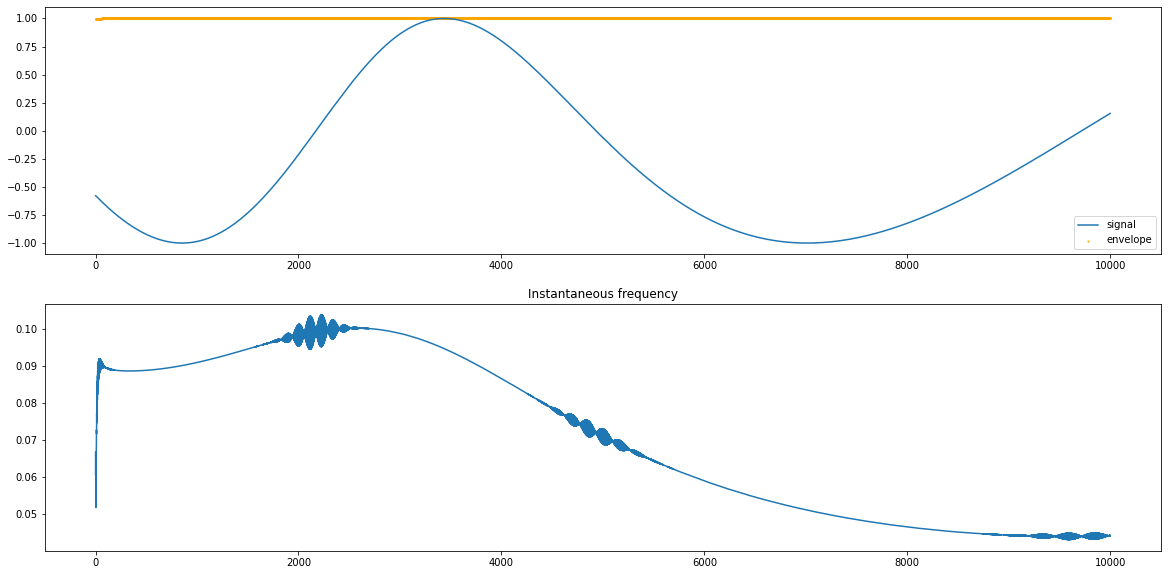

In [72]:
hilbert_path = "../data/hilbert"
hilbert_files = [file for file in os.listdir(hilbert_path) if file.endswith('.npy')]
reduced_imfs_path = "../data/reduced_imfs"
print(hilbert_files[0])
channel = 15
imf_index = 4

n_signal = np.load(os.path.join(reduced_imfs_path,hilbert_files[0]), allow_pickle=True)[channel][imf_index]
n_signal = normalize_IMF(n_signal)

HT = np.load(os.path.join(hilbert_path, hilbert_files[0]), allow_pickle=True)
analytic_signal = HT[channel][imf_index]
amplitude_envelope = np.abs(analytic_signal)
instantaneous_phase = np.unwrap(np.angle(analytic_signal))
instantaneous_frequency = (np.diff(instantaneous_phase) / (2.0*np.pi) * fs)

steps = 10000
fig = plt.figure(figsize=(20,10))
ax0 = fig.add_subplot(211)
ax0.plot(n_signal[:steps], label='signal')
ax0.scatter(np.arange(steps),amplitude_envelope[:steps], label='envelope', s=1, c="orange")
ax0.legend()
ax1 = fig.add_subplot(212)
ax1.set_title("Instantaneous frequency")
ax1.plot(instantaneous_frequency[:steps])
plt.show()

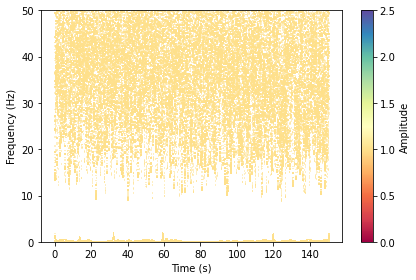

In [66]:
def plot_HS(time, frec_inst, amplitud, canal):
    fig = plt.figure(num=canal)
    ax = fig.add_subplot(1, 1, 1)
    for k in range(0, np.size(frec_inst, 0)):  # Para el canal
        frec = frec_inst[k]
        amp = amplitud[k][:-1]
        im = ax.scatter(time[:-1], frec, s=0.1, c=(amp), cmap='Spectral', vmin=0, vmax=2.5, marker=',', alpha=1)
    ax.set_ylim([0, 50])
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Frequency (Hz)')
    cb = fig.colorbar(im)
    cb.set_label('Amplitude')
    fig.tight_layout()
    plt.show()
    return

analytic_signal = HT[channel]
amplitude_envelope = np.abs(analytic_signal)
instantaneous_phase = np.unwrap(np.angle(analytic_signal))
instantaneous_frequency = (np.diff(instantaneous_phase) /
                           (2.0*np.pi) * fs)


time = np.arange(analytic_signal.shape[1]) / fs

plot_HS(time, instantaneous_frequency, amplitude_envelope, 0)

# Obtaining descriptors

### PAC connectivity with MVL

step4_get_pac.py

In [54]:
descriptors_path = "../data/descriptors"

In [55]:
descriptors_files = [file for file in os.listdir(descriptors_path) if file.endswith('.pickle')]

In [56]:
with open(os.path.join(descriptors_path, descriptors_files[0]), 'rb') as file:
    desc = pickle.load(file)        

key: tuple: (channel_x, channel_y)
values: matrix -> shape (#hilbert_transforms of channel x, #hilbert_transforms of channel y, 3) -> last shape item is (MVL, frequency1, frequency2)

In [75]:
for filename in descriptors_files:
    with open(os.path.join(descriptors_path, filename), 'rb') as file:
        desc = pickle.load(file)    
    for key, value in desc.items():
        if (value[:,:,0] > 1).any():
            print(filename, key, value[:,:,:])

7_2_C_5.pickle (5, 7) [[[0.00000000e+00 6.38529647e+01 6.73161726e+01]
  [0.00000000e+00 6.38529647e+01 4.12764192e-01]
  [0.00000000e+00 6.38529647e+01 1.93074658e-01]
  [0.00000000e+00 6.38529647e+01 1.06523931e-01]
  [0.00000000e+00 6.38529647e+01 5.32537445e-02]
  [0.00000000e+00 6.38529647e+01 1.99732530e-02]
  [0.00000000e+00 6.38529647e+01 6.65769955e-03]
  [0.00000000e+00 6.38529647e+01 8.75171053e-19]]

 [[0.00000000e+00 4.99342377e-01 6.73161726e+01]
  [0.00000000e+00 4.99342377e-01 4.12764192e-01]
  [0.00000000e+00 4.99342377e-01 1.93074658e-01]
  [0.00000000e+00 4.99342377e-01 1.06523931e-01]
  [0.00000000e+00 4.99342377e-01 5.32537445e-02]
  [0.00000000e+00 4.99342377e-01 1.99732530e-02]
  [0.00000000e+00 4.99342377e-01 6.65769955e-03]
  [0.00000000e+00 4.99342377e-01 8.75171053e-19]]

 [[0.00000000e+00 2.39679071e-01 6.73161726e+01]
  [0.00000000e+00 2.39679071e-01 4.12764192e-01]
  [0.00000000e+00 2.39679071e-01 1.93074658e-01]
  [0.00000000e+00 2.39679071e-01 1.06523931